In [4]:
#Ardıcıllıqları müqayisə etmək
seq1 = "MKTAYIAK"
seq2 = "MKTAYVAK"

matches = 0

for i in range(len(seq1)):
    if seq1[i] == seq2[i]:
        matches += 1

identity = matches / len(seq1) * 100

print("Matches:", matches)
print("Identity:", identity, "%")

Matches: 7
Identity: 87.5 %


In [5]:
#Multiple Sequence Alignment məntiqi
sequences = [
    "MKTAYIAK",
    "MKTAYVAK",
    "MKTAYIAK"
]

for sequence in sequences:
    print(sequence)

print("Number of sequences:", len(sequences))
print("Sequence length:", len(sequences[0]))

MKTAYIAK
MKTAYVAK
MKTAYIAK
Number of sequences: 3
Sequence length: 8


In [6]:
#Konservləşmiş mövqeləri tapmaq
sequences = [
    "MKTAYIAK",
    "MKTAYVAK",
    "MKTAYIAK"
]

length = len(sequences[0])

for i in range(length):
    column = []

    for sequence in sequences:
        column.append(sequence[i])

    most_common = max(set(column), key=column.count)
    identity = column.count(most_common) / len(sequences) * 100

    print("Position:", i + 1,
          "Most common:", most_common,
          "Identity:", identity, "%")

Position: 1 Most common: M Identity: 100.0 %
Position: 2 Most common: K Identity: 100.0 %
Position: 3 Most common: T Identity: 100.0 %
Position: 4 Most common: A Identity: 100.0 %
Position: 5 Most common: Y Identity: 100.0 %
Position: 6 Most common: I Identity: 66.66666666666666 %
Position: 7 Most common: A Identity: 100.0 %
Position: 8 Most common: K Identity: 100.0 %


In [7]:
#Gen funksiyasının annotasiyası
protein = {
    "name": "Example protein",
    "organism": "Example plant",
    "domain": "DNA-binding domain",
    "evidence": "Computational prediction"
}

print("Protein:", protein["name"])
print("Organism:", protein["organism"])
print("Domain:", protein["domain"])
print("Evidence:", protein["evidence"])

Protein: Example protein
Organism: Example plant
Domain: DNA-binding domain
Evidence: Computational prediction


In [8]:
#Ardıcıllıqlar arasındakı məsafə
sequences = {
    "Plant_A": "MKTAYIAK",
    "Plant_B": "MKTAYVAK",
    "Plant_C": "MKTAYIAK"
}

names = list(sequences.keys())

for i in range(len(names)):
    for j in range(i + 1, len(names)):
        seq1 = sequences[names[i]]
        seq2 = sequences[names[j]]

        differences = 0

        for k in range(len(seq1)):
            if seq1[k] != seq2[k]:
                differences += 1

        print(names[i], "vs", names[j],
              "Differences:", differences)

Plant_A vs Plant_B Differences: 1
Plant_A vs Plant_C Differences: 0
Plant_B vs Plant_C Differences: 1


In [9]:
#Filogenetik ağacı başa düşmək üçün sadə sxem
tree = """
        Ancestor
        /      \\
   Plant_A   Ancestor_2
              /      \\
         Plant_B    Plant_C
"""

print(tree)


        Ancestor
        /      \
   Plant_A   Ancestor_2
              /      \
         Plant_B    Plant_C



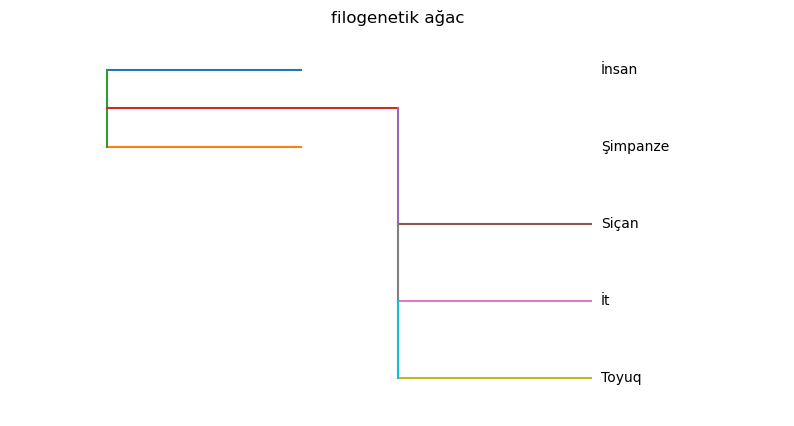

In [11]:
#Sadə filogenetik ağacı Python-da çəkmək
import matplotlib.pyplot as plt

# Növlərin ağacdakı şaquli mövqeləri
y = {
    "İnsan": 5,
    "Şimpanze": 4,
    "Siçan": 3,
    "İt": 2,
    "Toyuq": 1
}

# Budaqlar üçün koordinatlar
fig, ax = plt.subplots(figsize=(10, 5))

# İnsan və şimpanzenin budaqları
ax.plot([1, 3], [5, 5])
ax.plot([1, 3], [4, 4])
ax.plot([1, 1], [4, 5])

# İnsan-şimpanze qrupu ilə siçan
ax.plot([1, 4], [4.5, 4.5])
ax.plot([4, 4], [3, 4.5])
ax.plot([4, 6], [3, 3])

# İt və toyuq üçün sadə budaqlar
ax.plot([4, 6], [2, 2])
ax.plot([4, 4], [2, 3])
ax.plot([4, 6], [1, 1])
ax.plot([4, 4], [1, 2])

# Yarpaq adları
ax.text(6.1, 5, "İnsan", va="center")
ax.text(6.1, 4, "Şimpanze", va="center")
ax.text(6.1, 3, "Siçan", va="center")
ax.text(6.1, 2, "İt", va="center")
ax.text(6.1, 1, "Toyuq", va="center")

ax.set_title("filogenetik ağac")
ax.set_xlim(0, 8)
ax.set_ylim(0.5, 5.5)
ax.set_axis_off()

plt.show()

Protein A - fərqli mövqelər: 0
Protein B - fərqli mövqelər: 1
Protein C - fərqli mövqelər: 2


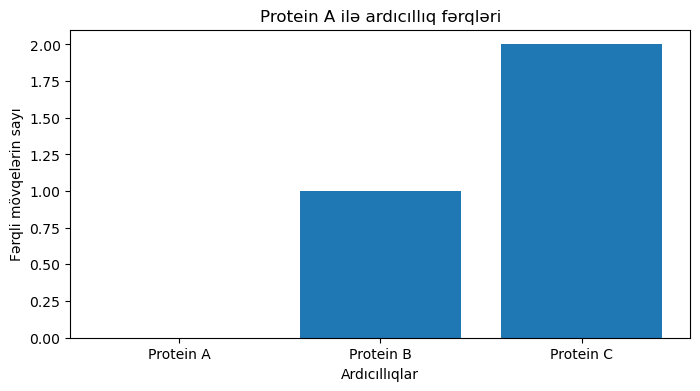

In [12]:
#Ardıcıllıqlar arasındakı fərqləri müqayisə etmək
import matplotlib.pyplot as plt

sequences = {
    "Protein A": "MKTAYIAK",
    "Protein B": "MKTAYVAK",
    "Protein C": "MKDAYVAK"
}

names = list(sequences.keys())
reference = sequences["Protein A"]
differences = []

for name in names:
    sequence = sequences[name]
    count = 0

    for i in range(len(reference)):
        if reference[i] != sequence[i]:
            count += 1

    differences.append(count)
    print(name, "- fərqli mövqelər:", count)

plt.figure(figsize=(8, 4))
plt.bar(names, differences)
plt.title("Protein A ilə ardıcıllıq fərqləri")
plt.ylabel("Fərqli mövqelərin sayı")
plt.xlabel("Ardıcıllıqlar")
plt.show()

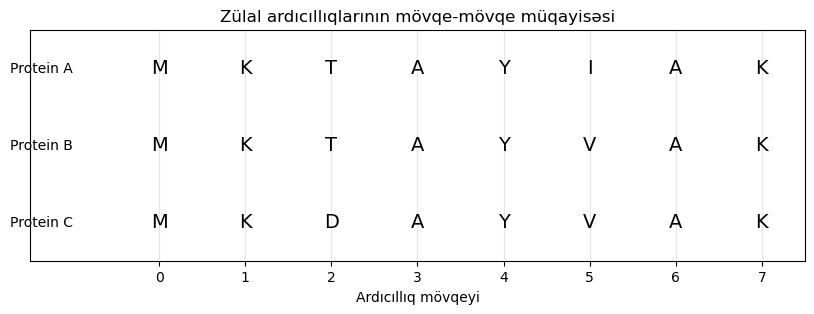

In [13]:
#Ardıcıllıqları alignment cədvəlində göstərmək
import matplotlib.pyplot as plt

sequences = {
    "Protein A": "MKTAYIAK",
    "Protein B": "MKTAYVAK",
    "Protein C": "MKDAYVAK"
}

fig, ax = plt.subplots(figsize=(10, 3))

for row, (name, seq) in enumerate(sequences.items()):
    for col, amino_acid in enumerate(seq):
        ax.text(
            col, 2 - row, amino_acid,
            ha="center", va="center", fontsize=14
        )

    ax.text(-1, 2 - row, name, ha="right", va="center")

ax.set_xlim(-1.5, len(next(iter(sequences.values()))) - 0.5)
ax.set_ylim(-0.5, 2.5)
ax.set_xticks(range(8))
ax.set_xlabel("Ardıcıllıq mövqeyi")
ax.set_title("Zülal ardıcıllıqlarının mövqe-mövqe müqayisəsi")
ax.set_yticks([])
ax.grid(axis="x", alpha=0.3)

plt.show()

[[0 1 2 1]
 [1 0 1 2]
 [2 1 0 1]
 [1 2 1 0]]


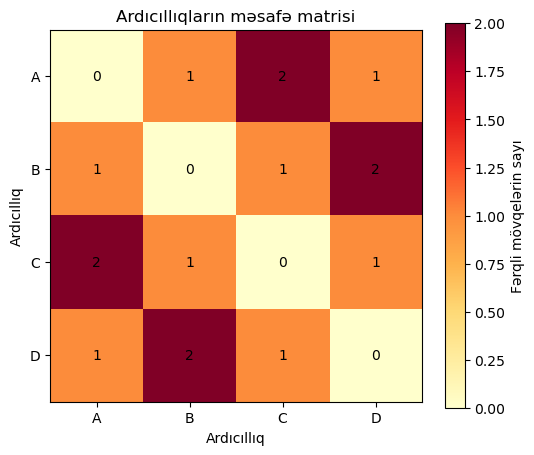

In [14]:
#Məsafə matrisi və istilik xəritəsi (heatmap)
import matplotlib.pyplot as plt
import numpy as np

sequences = {
    "A": "MKTAYIAK",
    "B": "MKTAYVAK",
    "C": "MKDAYVAK",
    "D": "MKDAYIAK"
}

names = list(sequences.keys())
n = len(names)

distance_matrix = np.zeros((n, n), dtype=int)

for i in range(n):
    for j in range(n):
        seq1 = sequences[names[i]]
        seq2 = sequences[names[j]]

        count = 0

        for k in range(len(seq1)):
            if seq1[k] != seq2[k]:
                count += 1

        distance_matrix[i, j] = count

print(distance_matrix)

plt.figure(figsize=(6, 5))
plt.imshow(distance_matrix, cmap="YlOrRd")

plt.xticks(range(n), names)
plt.yticks(range(n), names)
plt.colorbar(label="Fərqli mövqelərin sayı")

for i in range(n):
    for j in range(n):
        plt.text(
            j, i, str(distance_matrix[i, j]),
            ha="center", va="center"
        )

plt.title("Ardıcıllıqların məsafə matrisi")
plt.xlabel("Ardıcıllıq")
plt.ylabel("Ardıcıllıq")
plt.show()

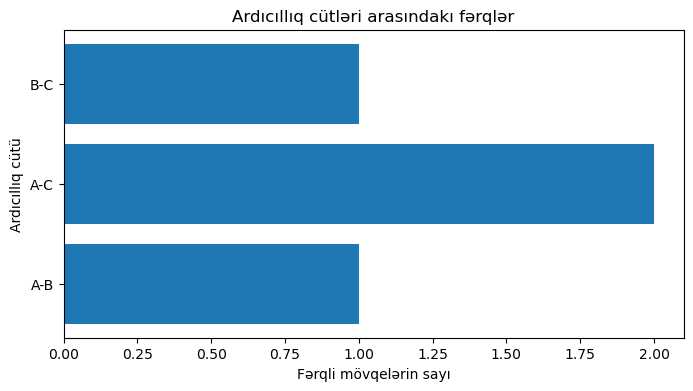

In [15]:
#Budaq uzunluğu nə deməkdir?
import matplotlib.pyplot as plt

pairs = ["A-B", "A-C", "B-C"]
differences = [1, 2, 1]

plt.figure(figsize=(8, 4))
plt.barh(pairs, differences)
plt.title("Ardıcıllıq cütləri arasındakı fərqlər")
plt.xlabel("Fərqli mövqelərin sayı")
plt.ylabel("Ardıcıllıq cütü")
plt.show()

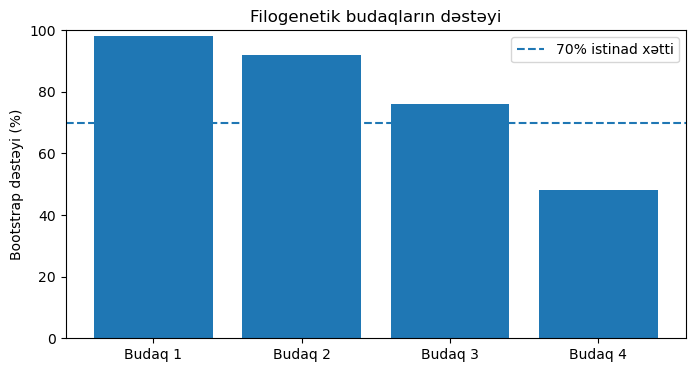

In [16]:
#Bootstrap dəstəyini vizuallaşdırmaq
import matplotlib.pyplot as plt

branches = [
    "Budaq 1",
    "Budaq 2",
    "Budaq 3",
    "Budaq 4"
]

support = [98, 92, 76, 48]

plt.figure(figsize=(8, 4))
plt.bar(branches, support)
plt.axhline(
    y=70,
    linestyle="--",
    label="70% istinad xətti"
)

plt.ylim(0, 100)
plt.ylabel("Bootstrap dəstəyi (%)")
plt.title("Filogenetik budaqların dəstəyi")
plt.legend()
plt.show()

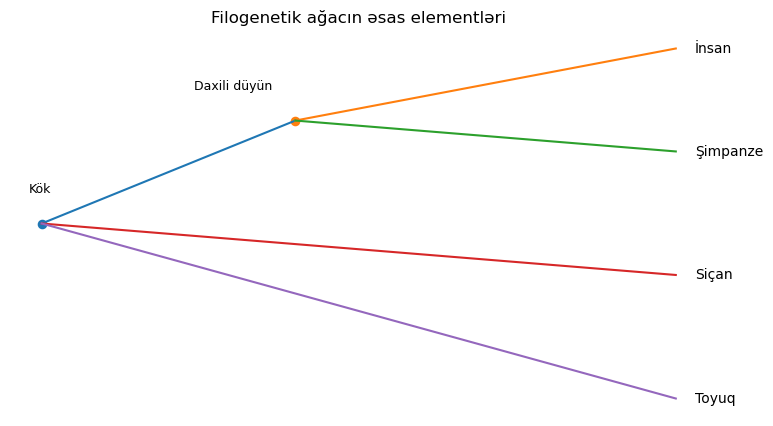

In [17]:
#Sadə ağac quruluşunu sxemlə göstərmək
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))

# Daxili düyünlər və yarpaqlar üçün koordinatlar
positions 
= {
    "root": (0, 2.5),
    "mammal_group": (2, 3.5),
    "human": (5, 4.2),
    "chimp": (5, 3.2),
    "mouse": (5, 2.0),
    "chicken": (5, 0.8)
}

edges = [
    ("root", "mammal_group"),
    ("mammal_group", "human"),
    ("mammal_group", "chimp"),
    ("root", "mouse"),
    ("root", "chicken")
]

for start, end in edges:
    x1, y1 = positions[start]
    x2, y2 = positions[end]
    ax.plot([x1, x2], [y1, y2])

labels = {
    "human": "İnsan",
    "chimp": "Şimpanze",
    "mouse": "Siçan",
    "chicken": "Toyuq"
}

for key, label in labels.items():
    x, y = positions[key]
    ax.text(x + 0.15, y, label, va="center")

for key in ["root", "mammal_group"]:
    x, y = positions[key]
    ax.scatter(x, y, s=35)

ax.text(-0.1, 2.8, "Kök", fontsize=9)
ax.text(1.2, 3.8, "Daxili düyün", fontsize=9)

ax.set_title("Filogenetik ağacın əsas elementləri")
ax.set_axis_off()
plt.show()